# Розвідувальний аналіз (EDA)

Перед побудовою моделі було досліджено навчальний і тестовий CSV-файли. У тестовому файлі немає мітки `Credit_Score`, тому аналіз цільової змінної виконується лише на навчальних даних.

Дані містять прямі ідентифікатори, зокрема імена та номери SSN. Їх виключено з відображуваних прикладів і не слід використовувати як ознаки моделі. Клієнти мають кілька місячних записів, тому для валідації потрібне розбиття за клієнтами.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)

data_dir = next(
    (path for path in (Path("data"), Path("../data")) if (path / "train.csv").is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Не вдалося знайти data/train.csv відносно робочої теки ноутбука.")

identifier_dtypes = {"ID": "string", "Customer_ID": "string", "SSN": "string"}
train = pd.read_csv(data_dir / "train.csv", dtype=identifier_dtypes, low_memory=False)
test = pd.read_csv(data_dir / "test.csv", dtype=identifier_dtypes, low_memory=False)
target = "Credit_Score"

print(f"Навчальні дані: {train.shape[0]:,} рядків × {train.shape[1]} стовпців")
print(f"Тестові дані:   {test.shape[0]:,} рядків × {test.shape[1]} стовпців")

Навчальні дані: 100,000 рядків × 28 стовпців
Тестові дані:   50,000 рядків × 27 стовпців


## Допоміжні функції для числових полів

Багато числових полів зчитуються як текст через зайві символи (`28_`, `34847.84_`, `__10000__`) і містять неможливі значення (вік −500 або 692, понад 1000 кредитів). Нижче задано допустимі діапазони (ті самі, що в `src/config.py`) і функції, які повертають «очищений» числовий вигляд даних. Вихідні таблиці `train` і `test` не змінюються.

In [4]:
VALID = {
    "Age": (14, 100), "Annual_Income": (0, 1_000_000), "Monthly_Inhand_Salary": (0, 20_000),
    "Num_Bank_Accounts": (0, 20), "Num_Credit_Card": (0, 20), "Interest_Rate": (1, 40),
    "Num_of_Loan": (0, 12), "Delay_from_due_date": (-10, 80), "Num_of_Delayed_Payment": (0, 30),
    "Changed_Credit_Limit": (-20, 50), "Num_Credit_Inquiries": (0, 30), "Outstanding_Debt": (0, 10_000),
    "Credit_Utilization_Ratio": (0, 100), "Credit_History_Age": (0, 600), "Total_EMI_per_month": (0, 5_000),
    "Amount_invested_monthly": (0, 5_000), "Monthly_Balance": (0, 5_000),
}


def to_number(series):
    """'34847.84_' -> 34847.84; '_' або сміття -> NaN."""
    text = series.astype("string").str.strip().str.replace("_", "", regex=False)
    return pd.to_numeric(text, errors="coerce").astype(float)


def history_months(series):
    """'22 Years and 1 Months' -> 265."""
    parts = series.astype("string").str.extract(r"(\d+)\s*Years?\s*and\s*(\d+)\s*Months?")
    return (pd.to_numeric(parts[0]) * 12 + pd.to_numeric(parts[1])).astype(float)


def parse_column(df, column):
    return history_months(df[column]) if column == "Credit_History_Age" else to_number(df[column])


def numeric_view(df):
    """Числові ознаки, де сміття та значення поза діапазоном замінено на NaN."""
    out = pd.DataFrame(index=df.index)
    for column, (low, high) in VALID.items():
        values = parse_column(df, column)
        out[column] = values.where(values.between(low, high))
    return out


train_num = numeric_view(train)
test_num = numeric_view(test)

## 1. Структура та схема даних

In [5]:
print("Стовпці лише в навчальних даних:", sorted(set(train.columns) - set(test.columns)))
print("Стовпці лише в тестових даних:   ", sorted(set(test.columns) - set(train.columns)))
display(train.drop(columns=["Name", "SSN", "ID", "Customer_ID"], errors="ignore").head())

schema = pd.DataFrame({
    "Тип даних": train.dtypes.astype(str),
    "Заповнених значень": train.notna().sum(),
    "Унікальних значень (з пропусками)": train.nunique(dropna=False),
}).sort_values("Тип даних")
display(schema)

Стовпці лише в навчальних даних: ['Credit_Score']
Стовпці лише в тестових даних:    []


,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,January,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4.0,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,February,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,NaN,11.27,4.0,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,March,-500,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,_,4.0,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,April,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4,6.27,4.0,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,May,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,NaN,11.27,4.0,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


,Тип даних,Заповнених значень,Унікальних значень (з пропусками)
Total_EMI_per_month,float64,100000,14950
Credit_Utilization_Ratio,float64,100000,100000
Monthly_Inhand_Salary,float64,84998,13236
Num_Credit_Inquiries,float64,98035,1224
Num_Bank_Accounts,int64,100000,943
Num_Credit_Card,int64,100000,1179
Interest_Rate,int64,100000,1750
Delay_from_due_date,int64,100000,73
Type_of_Loan,object,88592,6261
Payment_Behaviour,object,100000,7


Стовпці типу `object`, які за змістом є числами (`Age`, `Annual_Income`, `Num_of_Loan`, `Outstanding_Debt`, `Changed_Credit_Limit`, `Amount_invested_monthly`, `Monthly_Balance`), містять текстові домішки. Тому їх потрібно перетворювати перед аналізом і моделюванням.

## 2. Пропущені значення, маркери та дублікати

In [6]:
shared_columns = train.columns.intersection(test.columns)
missing = pd.DataFrame({
    "Пропуски в навчальних даних": train[shared_columns].isna().sum(),
    "Пропуски в навчальних даних, %": (100 * train[shared_columns].isna().mean()).round(2),
    "Пропуски в тестових даних": test[shared_columns].isna().sum(),
    "Пропуски в тестових даних, %": (100 * test[shared_columns].isna().mean()).round(2),
}).sort_values("Пропуски в навчальних даних, %", ascending=False)
display(missing.loc[missing[["Пропуски в навчальних даних", "Пропуски в тестових даних"]].max(axis=1).gt(0)])

# NM («Not Mentioned») у Payment_of_Min_Amount — допустиме значення, але не відповідь «так/ні»
placeholders = {"_", "__", "_______", "!@9#%8", "nm", "?", "null", "none"}
text_columns = train.select_dtypes(include=["object", "string"]).columns
placeholder_counts = {}
for column in text_columns:
    values = train[column].astype("string").str.strip().str.lower()
    count = int(values.isin(placeholders).sum())
    if count:
        placeholder_counts[column] = count
display(pd.Series(placeholder_counts, name="Кількість рядків із маркерами").sort_values(ascending=False).to_frame())

print(f"Повні дублікати навчальних рядків: {train.duplicated().sum():,}")
print(f"Дублікати ID у навчальних даних:   {train['ID'].duplicated().sum():,}")
print(f"Рядки без цільової мітки:          {train[target].isna().sum():,}")

,Пропуски в навчальних даних,"Пропуски в навчальних даних, %",Пропуски в тестових даних,"Пропуски в тестових даних, %"
Monthly_Inhand_Salary,15002,15.00,7498,15.00
Type_of_Loan,11408,11.41,5704,11.41
Name,9985,9.98,5015,10.03
Credit_History_Age,9030,9.03,4470,8.94
Num_of_Delayed_Payment,7002,7.00,3498,7.00
Amount_invested_monthly,4479,4.48,2271,4.54
Num_Credit_Inquiries,1965,1.96,1035,2.07
Monthly_Balance,1200,1.20,562,1.12


,Кількість рядків із маркерами
Credit_Mix,20195
Payment_of_Min_Amount,12007
Payment_Behaviour,7600
Occupation,7062
Changed_Credit_Limit,2091


Повні дублікати навчальних рядків: 0
Дублікати ID у навчальних даних:   0
Рядки без цільової мітки:          0


### Якість числових полів

Окрім звичайних пропусків, у числових полях є три різні проблеми: **нечислові значення** (наприклад, `_`), **числа з підкресленням** (`28_`, їх можна відновити) і **значення поза допустимим діапазоном** (вік −500, 1496 кредитів, маркер `__10000__`). Остання колонка показує частку придатних значень після очищення.

In [7]:
rows = {}
for column, (low, high) in VALID.items():
    raw = train[column]
    parsed = parse_column(train, column)
    rows[column] = {
        "Пропуски": int(raw.isna().sum()),
        "Нечислові значення": int((raw.notna() & parsed.isna()).sum()),
        "Числа з «_» (відновлено)": int((raw.astype("string").str.contains("_", na=False) & parsed.notna()).sum()),
        "Поза допустимим діапазоном": int((parsed.notna() & ~parsed.between(low, high)).sum()),
    }
quality = pd.DataFrame(rows).T
quality["Придатні значення, %"] = (100 * train_num.notna().mean()).round(1)
display(quality.sort_values("Придатні значення, %"))

,Пропуски,Нечислові значення,Числа з «_» (відновлено),Поза допустимим діапазоном,"Придатні значення, %"
Monthly_Inhand_Salary,15002,0,0,0,85.0
Credit_History_Age,9030,0,0,0,91.0
Amount_invested_monthly,4479,0,4305,4305,91.2
Num_of_Delayed_Payment,7002,0,2744,1380,91.6
Num_of_Loan,0,0,4785,4348,95.7
Num_Credit_Inquiries,1965,0,0,1648,96.4
Total_EMI_per_month,0,0,0,2988,97.0
Age,0,0,4939,2776,97.2
Num_Credit_Card,0,0,0,2263,97.7
Changed_Credit_Limit,0,2091,0,0,97.9


## 3. Цільова змінна, місяці та повторні записи клієнтів

,Кількість рядків,"Частка, %"
Credit_Score,,
Standard,53174,53.17
Poor,28998,29.00
Good,17828,17.83


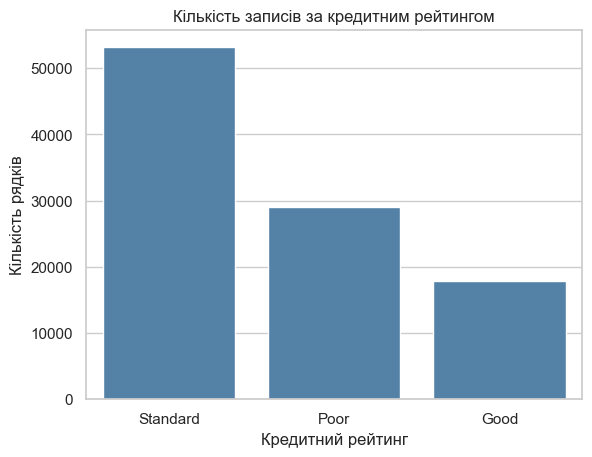

,Кількість рядків
Month,
Січень,12500.0
Лютий,12500.0
Березень,12500.0
Квітень,12500.0
Травень,12500.0
Червень,12500.0
Липень,12500.0
Серпень,12500.0


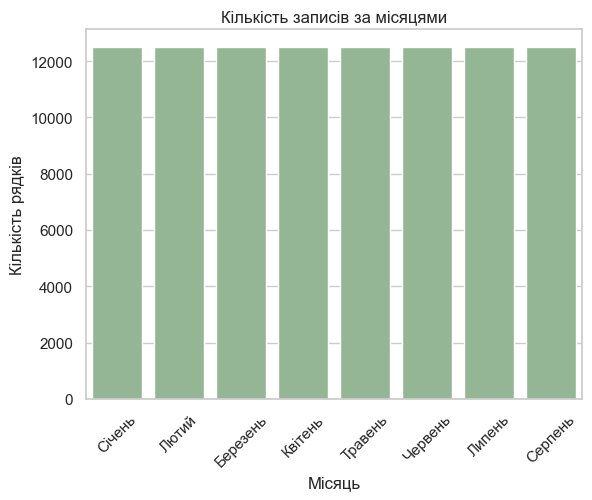

Унікальних клієнтів у навчальних даних: 12,500


,Кількість клієнтів
Рядків на клієнта,
8,12500


In [8]:
target_counts = train[target].value_counts(dropna=False)
display(pd.DataFrame({"Кількість рядків": target_counts, "Частка, %": (100 * target_counts / len(train)).round(2)}))
ax = sns.countplot(data=train, x=target, order=train[target].value_counts().index, color="steelblue")
ax.set(title="Кількість записів за кредитним рейтингом", xlabel="Кредитний рейтинг", ylabel="Кількість рядків")
plt.show()

month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
month_translation = dict(zip(month_order, ["Січень", "Лютий", "Березень", "Квітень", "Травень", "Червень", "Липень", "Серпень", "Вересень", "Жовтень", "Листопад", "Грудень"]))
month_counts = train["Month"].value_counts().reindex(month_order).dropna()
months_uk = train["Month"].map(month_translation)
order_uk = [month_translation[month] for month in month_counts.index]
display(month_counts.rename(index=month_translation).rename("Кількість рядків").to_frame())
ax = sns.countplot(x=months_uk, order=order_uk, color="darkseagreen")
ax.set(title="Кількість записів за місяцями", xlabel="Місяць", ylabel="Кількість рядків")
ax.tick_params(axis="x", rotation=45)
plt.show()

rows_per_customer = train.groupby("Customer_ID", dropna=False).size()
print(f"Унікальних клієнтів у навчальних даних: {train['Customer_ID'].nunique(dropna=True):,}")
display(rows_per_customer.value_counts().sort_index().rename_axis("Рядків на клієнта").to_frame("Кількість клієнтів"))

### Чи змінюється мітка в межах одного клієнта

Якщо мітка змінюється від місяця до місяця, то це оцінка конкретного місячного запису, а не постійна характеристика людини. Це впливає на постановку задачі та на валідацію.

In [9]:
labels_per_customer = train.groupby("Customer_ID")[target].nunique()
changing = int((labels_per_customer > 1).sum())
print(f"Клієнтів зі змінною міткою: {changing:,} з {len(labels_per_customer):,} ({100 * changing / len(labels_per_customer):.1f}%)")
display(labels_per_customer.value_counts().sort_index().rename_axis("Різних міток у клієнта").to_frame("Кількість клієнтів"))

Клієнтів зі змінною міткою: 7,292 з 12,500 (58.3%)


,Кількість клієнтів
Різних міток у клієнта,
1,5208
2,7262
3,30


## 4. Розподіли числових ознак

Підсумок і графіки побудовано за очищеним числовим виглядом (`train_num`): підкреслення прибрано, а неможливі значення замінено на пропуски. Без цього поля на кшталт `Age` чи `Num_of_Loan` через викиди нечитабельні.

,count,mean,std,min,1%,25%,50%,75%,99%,max
Age,97224.0,33.32,10.78,14.00,14.00,24.00,33.00,42.00,55.00,100.00
Annual_Income,99039.0,50695.44,39828.50,7005.93,7531.86,19355.62,37002.58,71690.05,167489.40,952323.00
Monthly_Inhand_Salary,84998.0,4194.17,3183.69,303.65,531.88,1625.57,3093.75,5957.45,13814.93,15204.63
Num_Bank_Accounts,98665.0,5.37,2.59,0.00,0.00,3.00,5.00,7.00,10.00,18.00
Num_Credit_Card,97737.0,5.53,2.07,0.00,1.00,4.00,5.00,7.00,10.00,20.00
Interest_Rate,97966.0,14.53,8.74,1.00,1.00,7.00,13.00,20.00,34.00,34.00
Num_of_Loan,95652.0,3.53,2.45,0.00,0.00,2.00,3.00,5.00,9.00,9.00
Delay_from_due_date,100000.0,21.07,14.86,-5.00,0.00,10.00,18.00,28.00,61.00,67.00
Num_of_Delayed_Payment,91618.0,13.42,6.21,0.00,0.00,9.00,14.00,18.00,25.00,28.00
Changed_Credit_Limit,97909.0,10.39,6.79,-6.49,-1.54,5.32,9.40,14.87,28.81,36.97


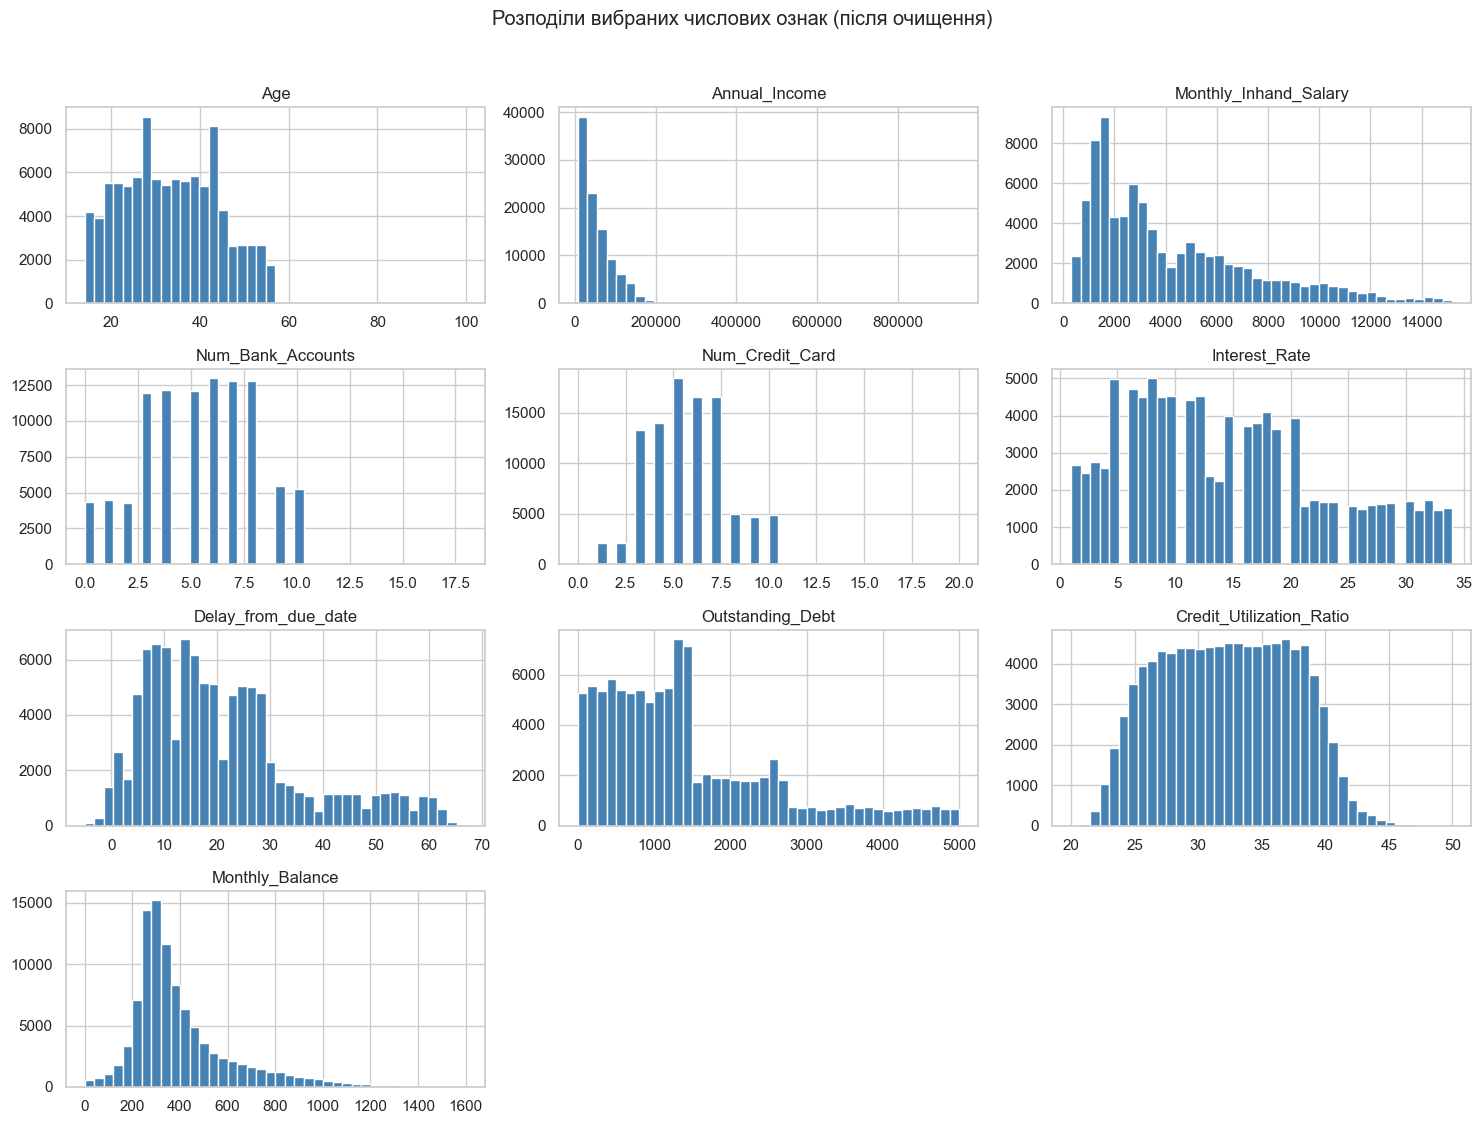

In [10]:
display(train_num.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2))

plot_columns = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts", "Num_Credit_Card",
    "Interest_Rate", "Delay_from_due_date", "Outstanding_Debt", "Credit_Utilization_Ratio", "Monthly_Balance",
]
train_num[plot_columns].hist(figsize=(15, 11), bins=40, color="steelblue", edgecolor="white", layout=(4, 3))
plt.suptitle("Розподіли вибраних числових ознак (після очищення)", y=1.02)
plt.tight_layout()
plt.show()

## 5. Розподіли категоріальних ознак

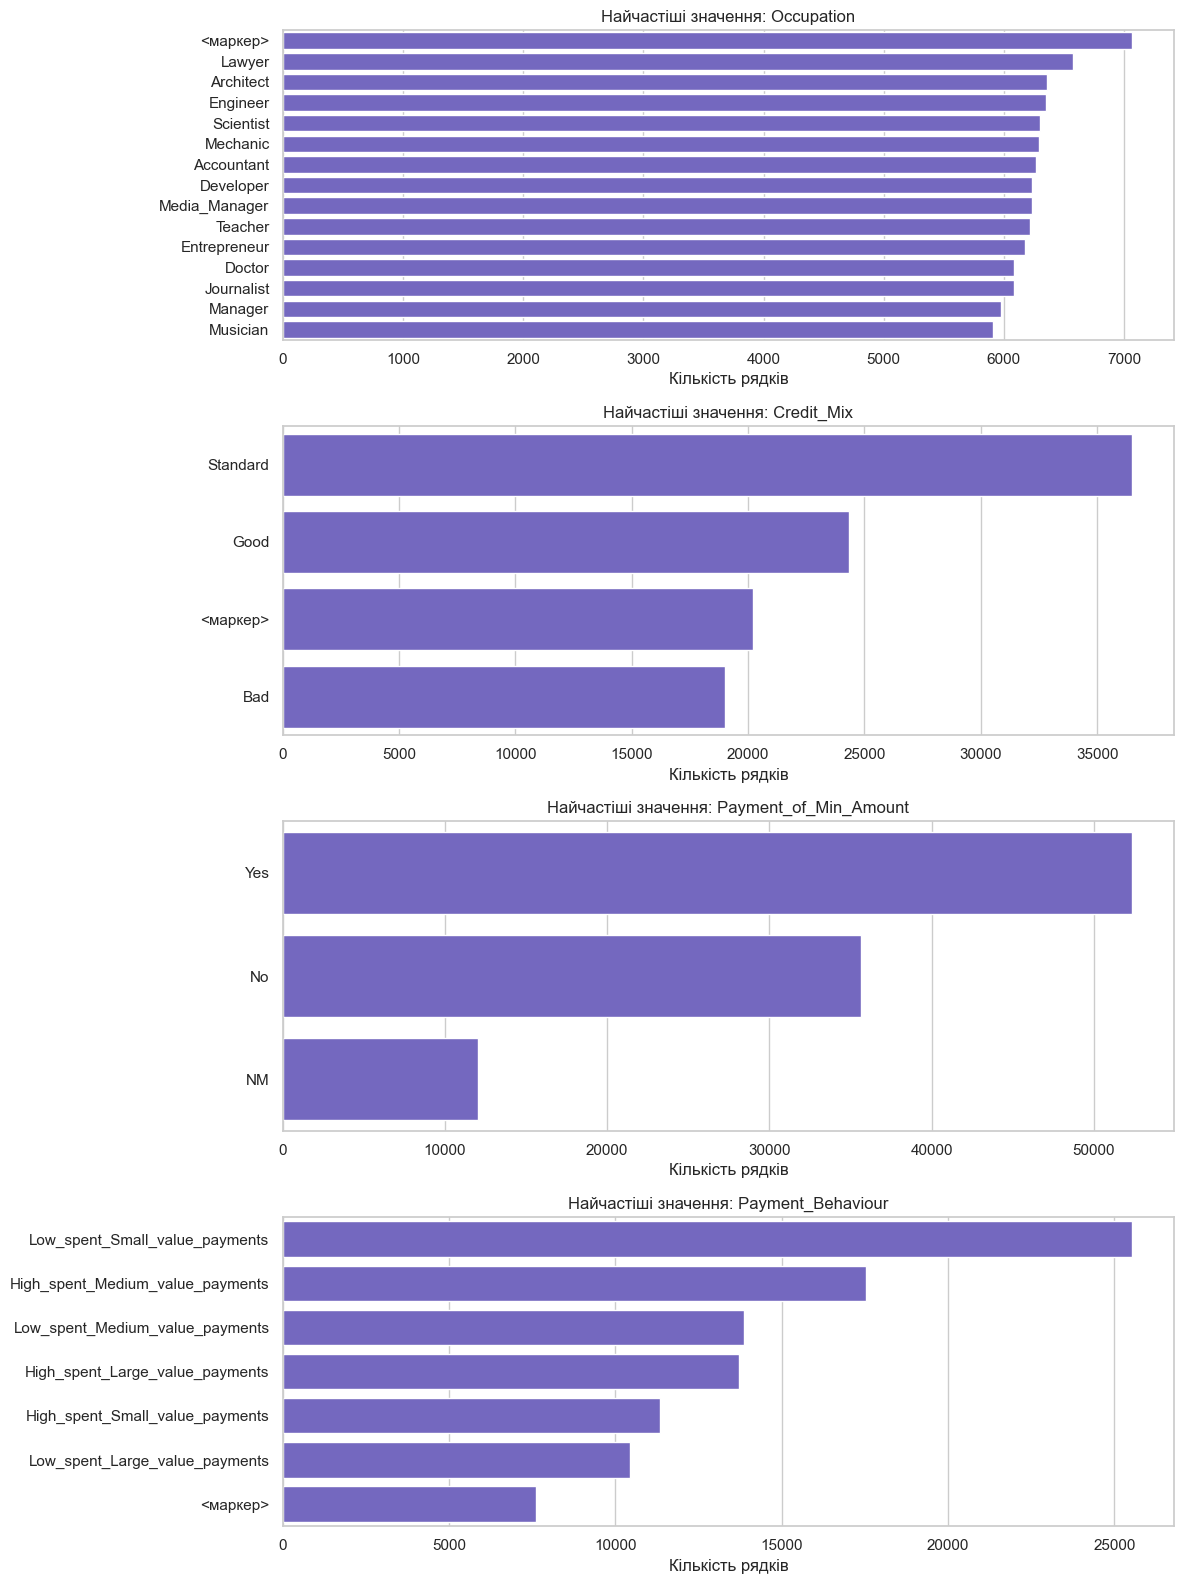

Occupation: 16 унікальних значень
Credit_Mix: 4 унікальних значень
Payment_of_Min_Amount: 3 унікальних значень
Payment_Behaviour: 7 унікальних значень


In [11]:
categorical_columns = ["Occupation", "Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour"]
garbage = {"_", "_______", "!@9#%8"}
fig, axes = plt.subplots(len(categorical_columns), 1, figsize=(12, 4 * len(categorical_columns)))
for ax, column in zip(axes, categorical_columns):
    values = train[column].astype("string").str.strip()
    values = values.mask(values.isin(garbage), "<маркер>").fillna("<пропуск>")
    order = values.value_counts().head(15).index
    sns.countplot(y=values, order=order, ax=ax, color="slateblue")
    ax.set(title=f"Найчастіші значення: {column}", xlabel="Кількість рядків", ylabel="")
plt.tight_layout()
plt.show()

for column in categorical_columns:
    print(f"{column}: {train[column].nunique(dropna=False)} унікальних значень")

## 6. Зв’язок ознак із цільовою змінною

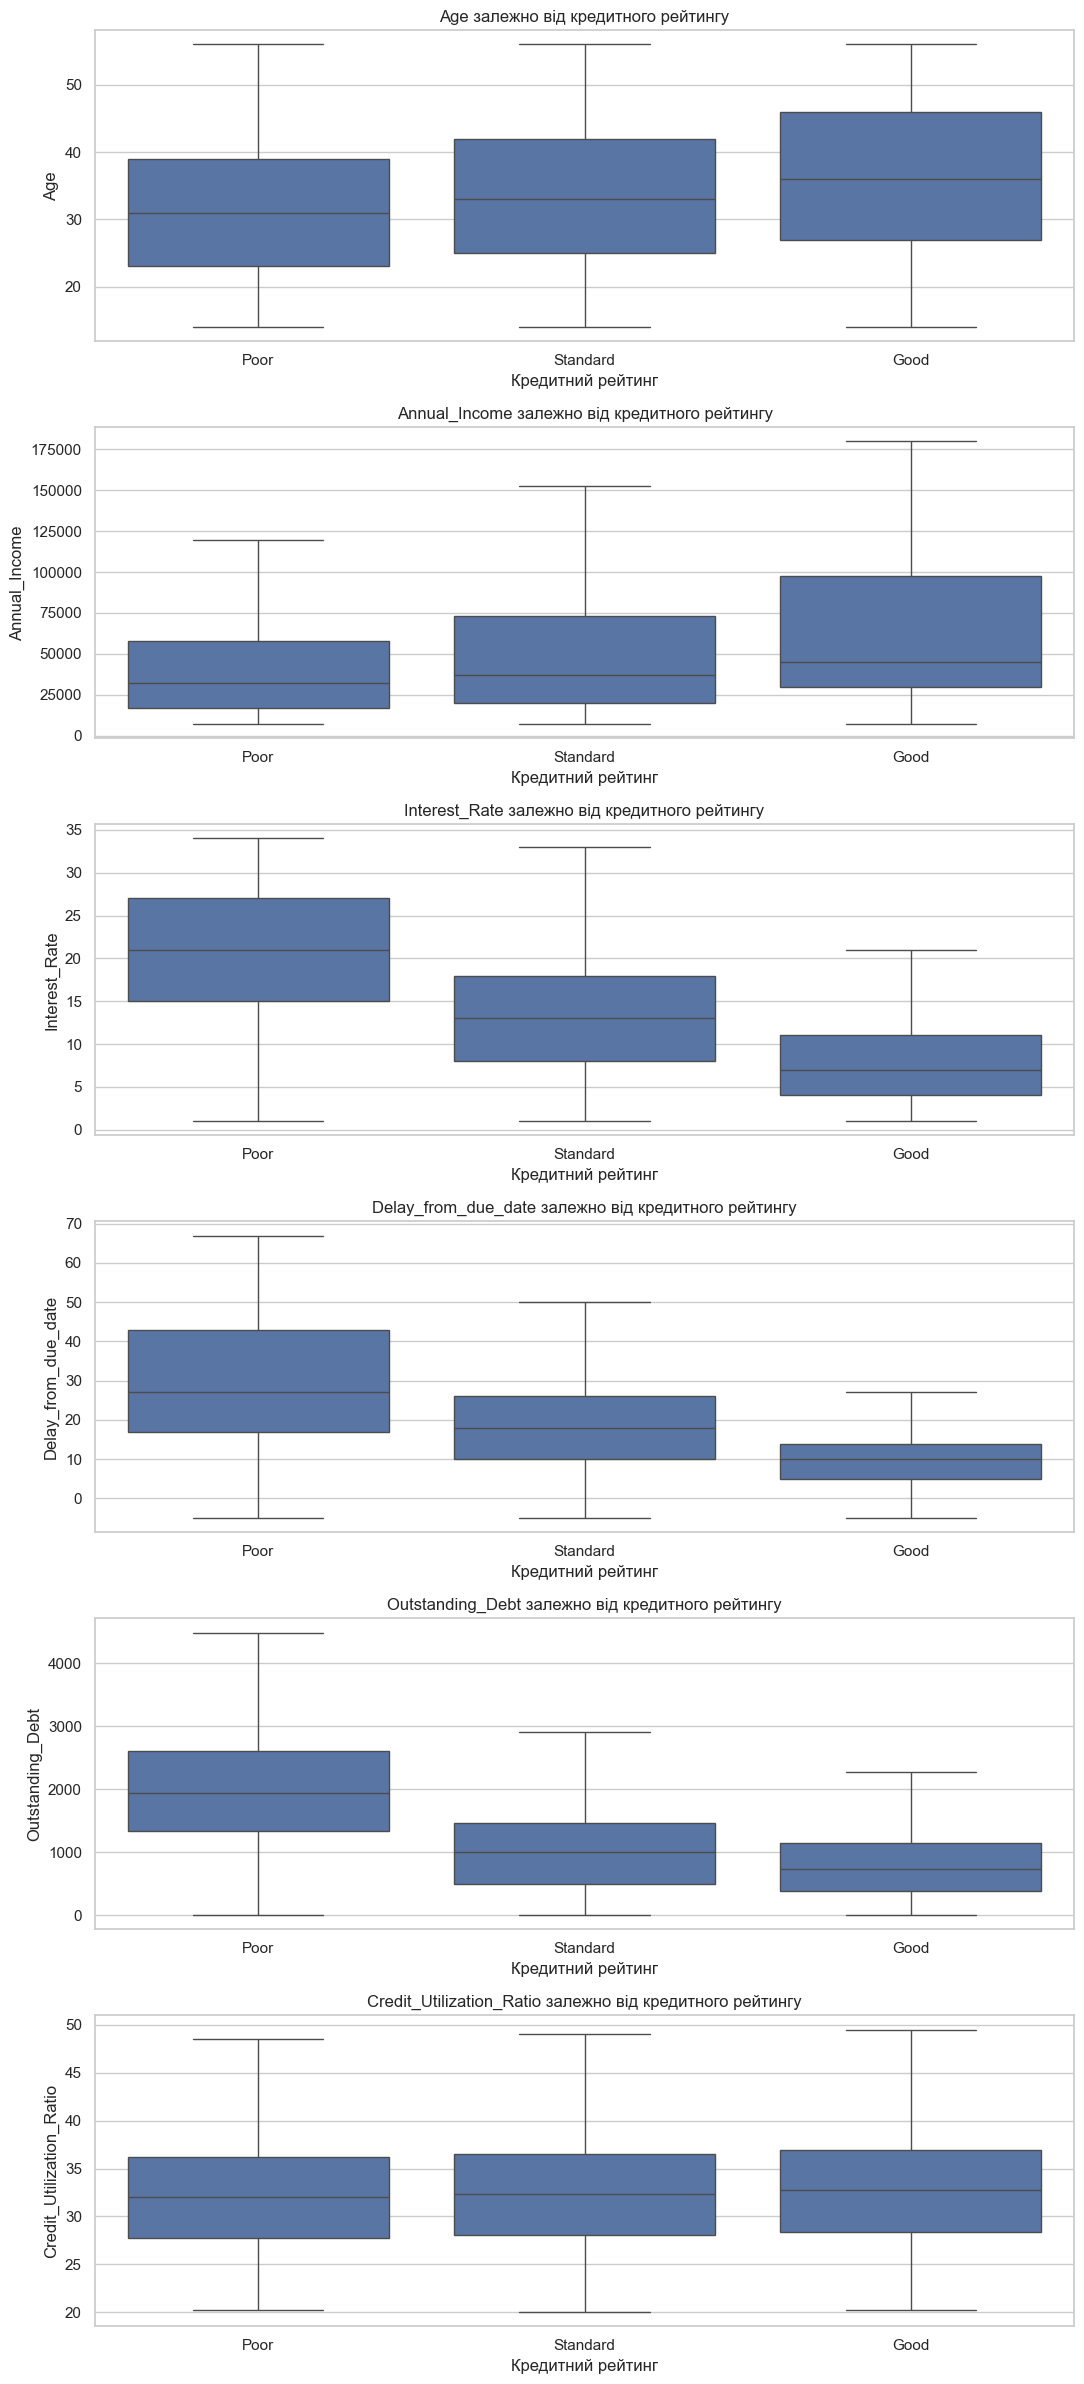

In [12]:
relationship_columns = ["Age", "Annual_Income", "Interest_Rate", "Delay_from_due_date", "Outstanding_Debt", "Credit_Utilization_Ratio"]
fig, axes = plt.subplots(len(relationship_columns), 1, figsize=(11, 4 * len(relationship_columns)))
for ax, column in zip(axes, relationship_columns):
    plot_data = pd.DataFrame({target: train[target], column: train_num[column]}).dropna()
    sns.boxplot(data=plot_data, x=target, y=column, order=["Poor", "Standard", "Good"], ax=ax, showfliers=False)
    ax.set(title=f"{column} залежно від кредитного рейтингу", xlabel="Кредитний рейтинг", ylabel=column)
plt.tight_layout()
plt.show()

## 7. Кореляції числових ознак

Використано очищений числовий вигляд плюс цільову змінну, закодовану як 0 (Poor), 1 (Standard), 2 (Good). Кореляція не відображає нелінійних зв’язків і не є доказом причинності.

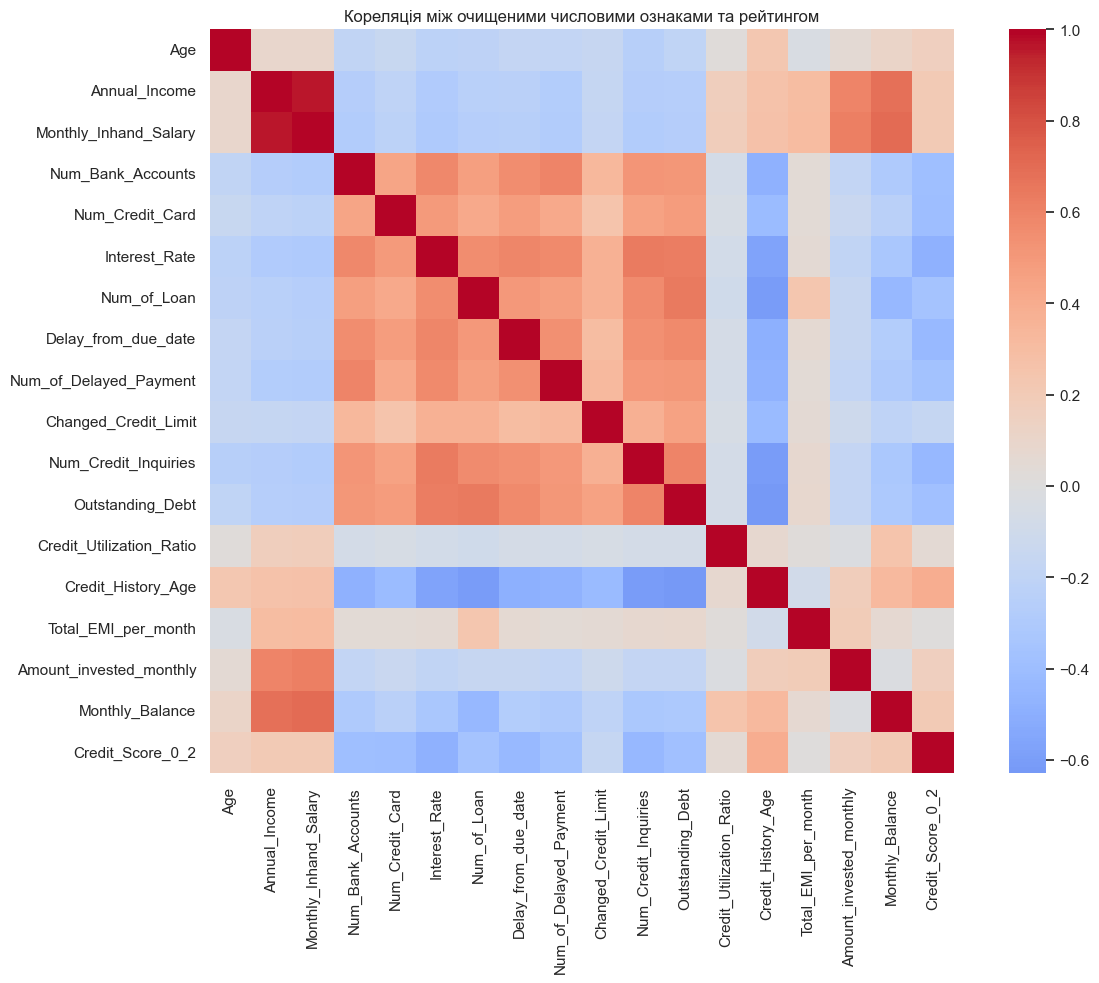

,Кореляція з рейтингом (0–2)
Interest_Rate,-0.485
Num_Credit_Inquiries,-0.435
Delay_from_due_date,-0.432
Num_Credit_Card,-0.404
Credit_History_Age,0.389
Num_Bank_Accounts,-0.389
Outstanding_Debt,-0.387
Num_of_Delayed_Payment,-0.370
Num_of_Loan,-0.357
Monthly_Inhand_Salary,0.209


In [13]:
corr_frame = train_num.assign(Credit_Score_0_2=train[target].map({"Poor": 0, "Standard": 1, "Good": 2}))
correlations = corr_frame.corr()
plt.figure(figsize=(13, 10))
sns.heatmap(correlations, cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Кореляція між очищеними числовими ознаками та рейтингом")
plt.tight_layout()
plt.show()

with_target = correlations["Credit_Score_0_2"].drop("Credit_Score_0_2")
display(with_target.sort_values(key=abs, ascending=False).round(3).to_frame("Кореляція з рейтингом (0–2)"))

## 8. Порівняння навчальних і тестових даних

Навчальні й тестові файли можуть містити записи різних клієнтів, тому перед валідацією варто перевірити, чи вони схожі за розподілами. Частка «недійсних або пропущених» значень включає і пропуски, і сміття, і викиди.

In [14]:
comparison_columns = ["Age", "Annual_Income", "Monthly_Inhand_Salary", "Interest_Rate", "Outstanding_Debt", "Credit_Utilization_Ratio"]
comparison = {}
for column in comparison_columns:
    comparison[column] = {
        "Медіана навчальних даних": train_num[column].median(),
        "Медіана тестових даних": test_num[column].median(),
        "Недійсні або пропущені в навчальних, %": 100 * train_num[column].isna().mean(),
        "Недійсні або пропущені в тестових, %": 100 * test_num[column].isna().mean(),
    }
display(pd.DataFrame(comparison).T.round(2))

,Медіана навчальних даних,Медіана тестових даних,"Недійсні або пропущені в навчальних, %","Недійсні або пропущені в тестових, %"
Age,33.00,33.00,2.78,2.80
Annual_Income,37002.58,36993.94,0.96,0.97
Monthly_Inhand_Salary,3093.75,3086.30,15.00,15.00
Interest_Rate,13.00,13.00,2.03,1.93
Outstanding_Debt,1166.16,1166.16,0.00,0.00
Credit_Utilization_Ratio,32.31,32.28,0.00,0.00


## Висновки перед моделюванням

- **Маркери й сміття.** Значення `_`, `_______`, `!@9#%8`, підкреслення в числах і неможливі числові значення не можна вважати коректними категоріями чи вимірюваннями. Їх слід перетворювати на пропуски (діапазони задано в `VALID`). Значення `NM` у `Payment_of_Min_Amount` — окрема категорія.
- **Ідентифікатори.** `ID`, `Customer_ID`, `Name` і `SSN` не можна використовувати як ознаки.
- **Валідація.** Кожен клієнт має 8 місячних записів, тому розбиття та крос-валідацію потрібно робити за `Customer_ID`, щоб один клієнт не потрапляв одночасно в навчальну й валідаційну частини.
- **Мітка в межах клієнта змінюється.** Для більшості клієнтів рейтинг різний у різні місяці, тож модель оцінює місячний запис, а не постійну характеристику клієнта.
- **Дисбаланс класів.** Standard — приблизно 53%, Poor — 29%, Good — 18%. Потрібні вагові коефіцієнти класів і метрики, що не залежать від балансу (macro-F1, ROC-AUC).
- **Пропуски.** Найбільше їх у `Monthly_Inhand_Salary` (15%), а також у `Credit_History_Age` і `Num_of_Delayed_Payment`. Імп’ютери й кодувальники потрібно підганяти лише на навчальній частині кожного фолду.
- **Навчальні й тестові дані схожі** за медіанами та часткою недійсних значень, тож суттєвого зсуву розподілів не видно.